# DATA3001 Region A Preliminary Analysis

This notebook converts the `regionA_final.py` workflow into cells that can be
run one at a time. It analyses Global Drifter Program observations in Region A
(125–135°E, 25–35°N), checks data quality, estimates velocity when the CSV does
not contain `ve` and `vn`, and produces two preliminary figures.

**Data requirement:** `data/regions/region_A.csv` is kept locally and is not
uploaded to GitHub because it is a large downloaded data file.

## 1. Imports and configuration

Run the notebook from the repository root. Figures are saved under
`outputs/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LON_MIN, LON_MAX = 125.0, 135.0
LAT_MIN, LAT_MAX = 25.0, 35.0
EARTH_RADIUS_M = 6_371_000.0


def find_project_root(start: Path | None = None) -> Path:
    """Find the repository containing data/regions/region_A.csv."""
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "regions" / "region_A.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/regions/region_A.csv. Start JupyterLab from the "
        "data3001-project folder and make sure the CSV is present."
    )


PROJECT_DIR = find_project_root()
DATA_PATH = PROJECT_DIR / "data" / "regions" / "region_A.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Data:", DATA_PATH)
print("Figures:", OUTPUT_DIR)

Matplotlib is building the font cache; this may take a moment.


Project: /private/tmp/data3001-notebook-worktree.VglIiv
Data: /private/tmp/data3001-notebook-worktree.VglIiv/data/regions/region_A.csv
Figures: /private/tmp/data3001-notebook-worktree.VglIiv/outputs/figures


## 2. Load the Region A CSV

NOAA ERDDAP exports may contain a units row immediately below the header. The
cell detects and skips that row automatically.

In [2]:
preview = pd.read_csv(DATA_PATH, nrows=1, low_memory=False)
skip_units = False
if "latitude" in preview.columns and not preview.empty:
    skip_units = pd.isna(
        pd.to_numeric(preview.loc[0, "latitude"], errors="coerce")
    )

raw = pd.read_csv(
    DATA_PATH,
    skiprows=[1] if skip_units else None,
    low_memory=False,
)

print(f"Loaded {len(raw):,} rows and {len(raw.columns)} columns")
print("Columns:", raw.columns.tolist())
raw.head()

Loaded 562,944 rows and 4 columns
Columns: ['ID', 'time', 'latitude', 'longitude']


,ID,time,latitude,longitude
0,116418,2015-08-23T21:00:00Z,25.25155,134.60040
1,116418,2015-08-23T22:00:00Z,25.26250,134.61234
2,116418,2015-08-23T23:00:00Z,25.27344,134.62427
3,116418,2015-08-24T00:00:00Z,25.28436,134.63625
4,116418,2015-08-24T01:00:00Z,25.29527,134.64825


## 3. Clean coordinates and calculate speed

If the downloaded file already contains eastward (`ve`) and northward (`vn`)
velocity, those fields are used. Otherwise, velocity is estimated from the
change between consecutive hourly positions of the same drifter.

In [3]:
required = {"ID", "time", "latitude", "longitude"}
missing_required = required.difference(raw.columns)
if missing_required:
    raise ValueError(f"Required columns are missing: {sorted(missing_required)}")

df = raw.copy()
df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")

for column in ["latitude", "longitude", "ve", "vn"]:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

df["lon"] = ((df["longitude"] + 180.0) % 360.0) - 180.0
df["lat"] = df["latitude"]
df = df.dropna(subset=["ID", "time", "lat", "lon"]).copy()
df = df.sort_values(["ID", "time"]).reset_index(drop=True)

if {"ve", "vn"}.issubset(df.columns):
    df["speed"] = np.hypot(df["ve"], df["vn"])
    speed_source = "provided ve/vn columns"
else:
    grouped = df.groupby("ID", sort=False)
    time_difference_s = grouped["time"].diff().dt.total_seconds()
    previous_lat = grouped["lat"].shift()
    previous_lon = grouped["lon"].shift()

    latitude_change = np.deg2rad(df["lat"] - previous_lat)
    longitude_change = np.deg2rad(df["lon"] - previous_lon)
    mean_latitude = np.deg2rad((df["lat"] + previous_lat) / 2.0)

    # Only use steps that are approximately one hour apart.
    valid_hourly_step = time_difference_s.between(0.5 * 3600, 1.5 * 3600)
    df["vn"] = np.where(
        valid_hourly_step,
        EARTH_RADIUS_M * latitude_change / time_difference_s,
        np.nan,
    )
    df["ve"] = np.where(
        valid_hourly_step,
        EARTH_RADIUS_M * np.cos(mean_latitude) * longitude_change
        / time_difference_s,
        np.nan,
    )
    df["speed"] = np.hypot(df["ve"], df["vn"])
    speed_source = "estimated from consecutive positions"

print("Rows after cleaning:", f"{len(df):,}")
print("Speed source:", speed_source)
df.head()

Rows after cleaning: 562,944
Speed source: estimated from consecutive positions


,ID,time,latitude,longitude,lon,lat,vn,ve,speed
0,4888,2002-10-09 00:00:00+00:00,34.90803,129.26541,129.26541,34.90803,NaN,NaN,NaN
1,4888,2002-10-09 01:00:00+00:00,34.93290,129.28381,129.28381,34.93290,0.768172,0.466000,0.898468
2,4888,2002-10-09 02:00:00+00:00,34.95778,129.30219,129.30219,34.95778,0.768480,0.465353,0.898396
3,4888,2002-10-09 03:00:00+00:00,34.98266,129.32048,129.32048,34.98266,0.768480,0.462934,0.897145
4,35554,2012-09-02 06:00:00+00:00,26.54376,125.00968,125.00968,26.54376,NaN,NaN,NaN


## 4. Dataset overview

In [4]:
overview = pd.Series(
    {
        "observations": len(df),
        "unique_drifters": df["ID"].nunique(),
        "start_time": df["time"].min(),
        "end_time": df["time"].max(),
        "speed_source": speed_source,
    },
    name="Region A",
)
overview.to_frame()

,Region A
observations,562944
unique_drifters,521
start_time,1994-07-10 12:00:00+00:00
end_time,2022-10-31 00:00:00+00:00
speed_source,estimated from consecutive positions


## 5. Missing-value audit

In [5]:
qc_candidates = [
    "ID",
    "time",
    "latitude",
    "longitude",
    "ve",
    "vn",
    "err_lat",
    "err_lon",
    "err_ve",
    "err_vn",
    "gap",
    "location_type",
    "drogue_lost_date",
    "DrogueType",
    "DrogueCenterDepth",
]
qc_columns = [column for column in qc_candidates if column in df.columns]

missing_table = pd.DataFrame(
    {
        "missing_n": df[qc_columns].isna().sum(),
        "missing_pct": df[qc_columns].isna().mean().mul(100),
    }
).round(3)

missing_table

,missing_n,missing_pct
ID,0,0.000
time,0,0.000
latitude,0,0.000
longitude,0,0.000
ve,2058,0.366
vn,2058,0.366


## 6. Position and velocity summary

Extreme estimated speeds should be reviewed during later quality control; a
very large value can be caused by a position jump rather than a real current.

In [6]:
summary_columns = [
    column
    for column in [
        "latitude",
        "longitude",
        "ve",
        "vn",
        "speed",
        "err_lat",
        "err_lon",
        "err_ve",
        "err_vn",
    ]
    if column in df.columns
]

distribution_table = (
    df[summary_columns]
    .describe(percentiles=[0.01, 0.50, 0.90, 0.95, 0.99, 0.999])
    .T
)
distribution_table

,count,mean,std,min,1%,50%,90%,95%,99%,99.9%,max
latitude,562944.0,28.757969,2.368494,25.000015,25.067479,28.657914,31.941867,32.775669,34.710236,34.970983,34.999980
longitude,562944.0,130.098750,2.899442,125.000010,125.119380,130.087140,133.997874,134.498656,134.902223,134.990311,135.000000
ve,560886.0,0.112110,0.374559,-6.377160,-0.675055,0.073347,0.583077,0.784623,1.208263,1.776577,6.769670
vn,560886.0,0.107788,0.355494,-14.645607,-0.703617,0.082470,0.562152,0.737902,1.072104,1.490012,9.006480
speed,560886.0,0.437840,0.314887,0.000000,0.033460,0.361279,0.861599,1.062764,1.471833,2.019365,14.696967


## 7. Region boundary and positioning-system checks

In [7]:
outside_region = (
    ~df["lon"].between(LON_MIN, LON_MAX)
    | ~df["lat"].between(LAT_MIN, LAT_MAX)
)

boundary_check = pd.Series(
    {
        "outside_region_n": int(outside_region.sum()),
        "outside_region_pct": outside_region.mean() * 100,
    }
)
display(boundary_check.to_frame("value"))

if "location_type" in df.columns:
    location_counts = df["location_type"].value_counts(dropna=False)
    location_table = pd.DataFrame(
        {
            "count": location_counts,
            "percentage": (
                df["location_type"]
                .value_counts(normalize=True, dropna=False)
                .mul(100)
            ),
        }
    ).round(2)
    display(location_table)
else:
    print("location_type is not available in this CSV; this check was skipped.")

,value
outside_region_n,0.0
outside_region_pct,0.0


location_type is not available in this CSV; this check was skipped.


## 8. Speed distribution

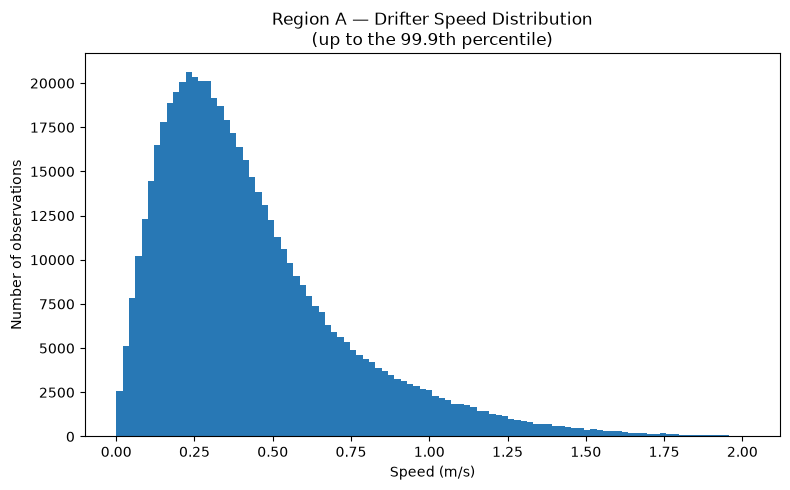

Saved: /private/tmp/data3001-notebook-worktree.VglIiv/outputs/figures/region_A_speed_distribution.png
Display limit (99.9th percentile): 2.019 m/s


In [8]:
speed_values = df["speed"].replace([np.inf, -np.inf], np.nan).dropna()
display_limit = speed_values.quantile(0.999)
speed_values_for_plot = speed_values[speed_values <= display_limit]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(speed_values_for_plot, bins=100, color="#2878B5", edgecolor="none")
ax.set_xlabel("Speed (m/s)")
ax.set_ylabel("Number of observations")
ax.set_title("Region A — Drifter Speed Distribution\n(up to the 99.9th percentile)")
fig.tight_layout()

speed_histogram_path = OUTPUT_DIR / "region_A_speed_distribution.png"
fig.savefig(speed_histogram_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", speed_histogram_path)
print(f"Display limit (99.9th percentile): {display_limit:.3f} m/s")

## 9. Optional high-resolution land-mask check

`global-land-mask` expands a compressed global grid in memory and may use
about 1 GB of RAM. It is disabled by default so that **Run All Cells** remains
safe on typical laptops. Change `USE_LAND_MASK` to `True` only when needed.

In [9]:
USE_LAND_MASK = False

if USE_LAND_MASK:
    from global_land_mask import globe

    is_land = globe.is_land(df["lat"].to_numpy(), df["lon"].to_numpy())
    land_observations = df.loc[is_land]
    land_summary = pd.Series(
        {
            "land_observations": len(land_observations),
            "land_percentage": 100 * len(land_observations) / len(df),
            "drifters_involved": land_observations["ID"].nunique(),
        }
    )
    display(land_summary.to_frame("value"))
else:
    print("Land-mask check skipped. Set USE_LAND_MASK = True to enable it.")

Land-mask check skipped. Set USE_LAND_MASK = True to enable it.


## 10. Spatial median-speed grid

Region A is divided into 0.25° cells. To limit unstable summaries from very
small samples, only cells with at least 50 valid speed observations are kept.

In [10]:
GRID_SIZE = 0.25
lon_bins = np.arange(LON_MIN, LON_MAX + GRID_SIZE, GRID_SIZE)
lat_bins = np.arange(LAT_MIN, LAT_MAX + GRID_SIZE, GRID_SIZE)

grid_data = df.copy()
grid_data["lon_cell"] = pd.cut(
    grid_data["lon"], lon_bins, labels=lon_bins[:-1], include_lowest=True
)
grid_data["lat_cell"] = pd.cut(
    grid_data["lat"], lat_bins, labels=lat_bins[:-1], include_lowest=True
)

speed_grid = (
    grid_data.groupby(["lon_cell", "lat_cell"], observed=True)
    .agg(n=("speed", "count"), median_speed=("speed", "median"))
    .reset_index()
)
speed_grid = speed_grid[speed_grid["n"] >= 50].copy()

n_cells = len(speed_grid)
speed_grid_summary = pd.Series(
    {
        "cells_with_n_at_least_50": n_cells,
        "median_speed_min": speed_grid["median_speed"].min(),
        "median_speed_median": speed_grid["median_speed"].median(),
        "median_speed_max": speed_grid["median_speed"].max(),
        "cells_above_0.6_m_s": int((speed_grid["median_speed"] > 0.6).sum()),
        "cells_above_0.8_m_s": int((speed_grid["median_speed"] > 0.8).sum()),
    }
)
speed_grid_summary.to_frame("value")

,value
cells_with_n_at_least_50,1332.000000
median_speed_min,0.074653
median_speed_median,0.330564
median_speed_max,1.359525
cells_above_0.6_m_s,129.000000
cells_above_0.8_m_s,56.000000


## 11. Spatial median-speed map

White cells may represent land, no observations, or fewer than 50 valid speed
observations. A coastline layer should be added before using this figure in a
report.

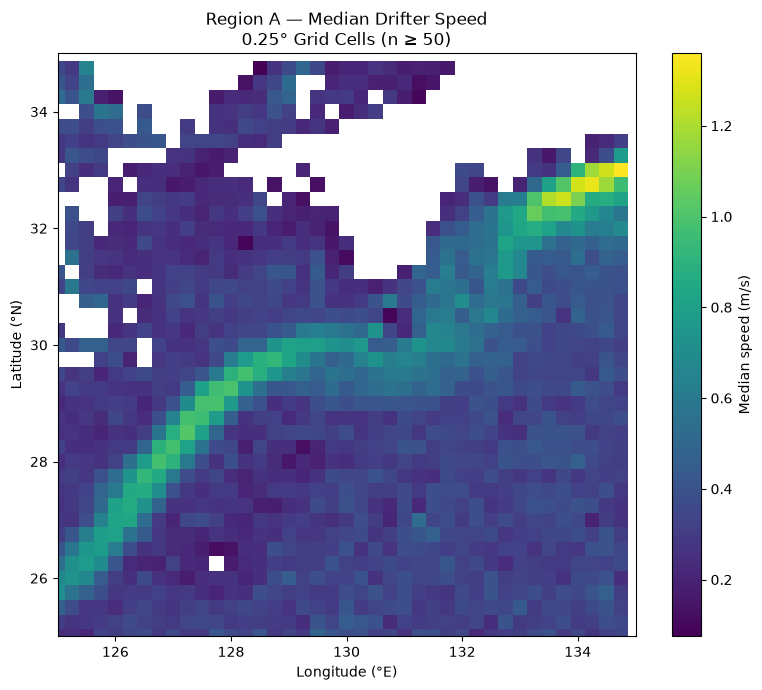

Saved: /private/tmp/data3001-notebook-worktree.VglIiv/outputs/figures/region_A_median_speed_map.png


In [11]:
plot_grid = speed_grid.copy()
plot_grid["lon_cell"] = plot_grid["lon_cell"].astype(float)
plot_grid["lat_cell"] = plot_grid["lat_cell"].astype(float)
speed_pivot = plot_grid.pivot(
    index="lat_cell", columns="lon_cell", values="median_speed"
)

fig, ax = plt.subplots(figsize=(8, 7))
mesh = ax.pcolormesh(
    speed_pivot.columns,
    speed_pivot.index,
    speed_pivot.values,
    shading="auto",
    cmap="viridis",
)
fig.colorbar(mesh, ax=ax, label="Median speed (m/s)")
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Region A — Median Drifter Speed\n0.25° Grid Cells (n ≥ 50)")
fig.tight_layout()

speed_map_path = OUTPUT_DIR / "region_A_median_speed_map.png"
fig.savefig(speed_map_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", speed_map_path)

## 12. Interpretation and next steps

The notebook establishes basic data availability and spatial speed structure;
it does **not** yet train a trajectory-forecasting model. The next stages are:

1. split each drifter record into continuous hourly trajectory segments;
2. construct samples using 24 h of history and 72 h of future ground truth;
3. partition drifters into train, calibration and test sets;
4. implement baseline and learned forecasting models; and
5. evaluate forecast error and uncertainty across dynamical regimes.

In [12]:
print("Analysis completed successfully.")
print("Figures are available in:", OUTPUT_DIR)

Analysis completed successfully.
Figures are available in: /private/tmp/data3001-notebook-worktree.VglIiv/outputs/figures
